In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.graphics.factorplots import interaction_plot

In [ ]:
diet_df = pd.read_excel('Diet_R (2).xlsx')
diet_df['gender'] = pd.to_numeric(diet_df['gender'], errors='coerce')
diet_df.dropna(subset=['gender'], inplace=True)

In [ ]:
diet_df['weightloss'] = diet_df['pre.weight'] - diet_df['weight6weeks']

In [ ]:
diet_df['AgeGroup'] = pd.qcut(diet_df['Age'], q=3, labels=['Young', 'Middle', 'Senior'])

In [ ]:
diet_df['HeightGroup'] = pd.qcut(diet_df['Height'], q=3, labels=['Short', 'Average', 'Tall'])
print(diet_df[['Age', 'AgeGroup', 'Height', 'HeightGroup', 'weightloss']].head())

   Age AgeGroup  Height HeightGroup  weightloss
2   22    Young     159       Short         3.8
3   46   Senior     192        Tall         6.0
4   55   Senior     170     Average         0.7
5   33    Young     171     Average         2.9
6   50   Senior     170     Average         2.8


/tmp/ipykernel_11078/2942603212.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(diet_df[diet_df.AgeGroup == 'Young'].weightloss, label='Young')
/tmp/ipykernel_11078/2942603212.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(diet_df[diet_df.AgeGroup == 'Middle'].weightloss, label='Middle'

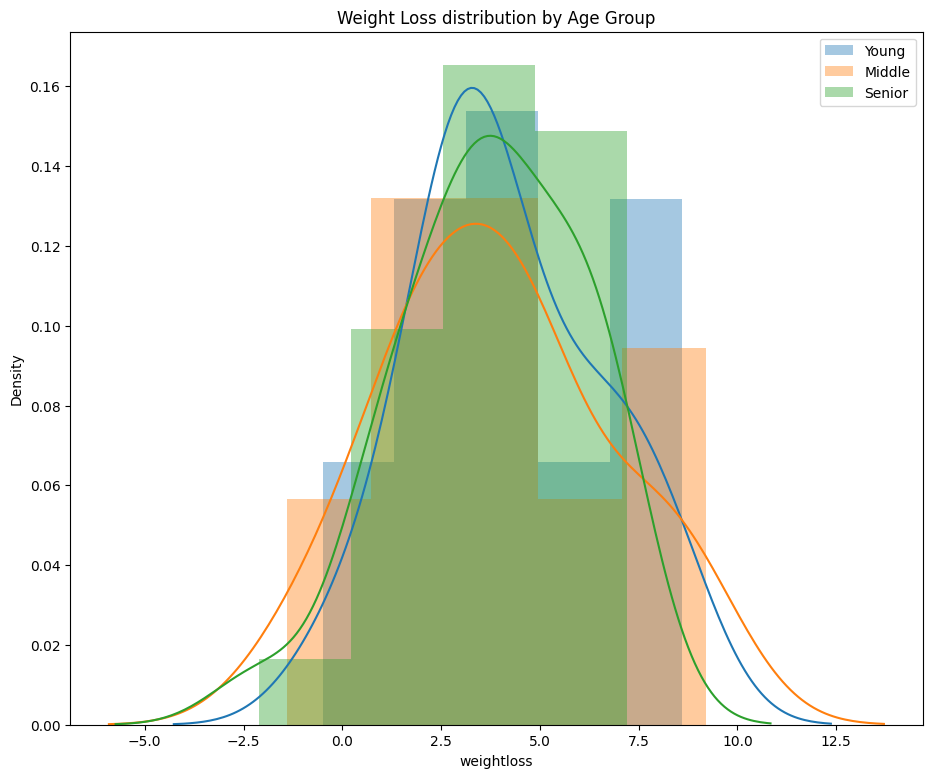

In [ ]:
f, ax = plt.subplots(figsize=(11, 9))
sns.distplot(diet_df[diet_df.AgeGroup == 'Young'].weightloss, label='Young')
sns.distplot(diet_df[diet_df.AgeGroup == 'Middle'].weightloss, label='Middle')
sns.distplot(diet_df[diet_df.AgeGroup == 'Senior'].weightloss, label='Senior')
plt.title('Weight Loss distribution by Age Group')
plt.ylabel('Density')
plt.legend()
plt.show()

One-Way ANOVA (AgeGroup) F-statistic: 0.18792356959432382
One-Way ANOVA (AgeGroup) P-value: 0.8290776568469655


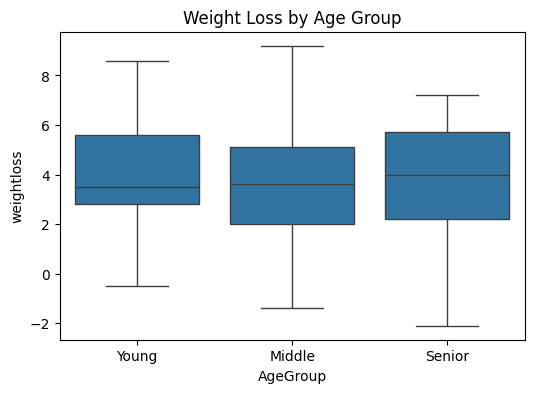

In [ ]:
age1_group = diet_df[diet_df['AgeGroup'] == 'Young']['weightloss']
age2_group = diet_df[diet_df['AgeGroup'] == 'Middle']['weightloss']
age3_group = diet_df[diet_df['AgeGroup'] == 'Senior']['weightloss']

f_stat, p_val = stats.f_oneway(age1_group, age2_group, age3_group)
print(f"One-Way ANOVA (AgeGroup) F-statistic:", f_stat)
print(f"One-Way ANOVA (AgeGroup) P-value:", p_val)

plt.figure(figsize=(6, 4))
sns.boxplot(x='AgeGroup', y='weightloss', data=diet_df)
plt.title('Weight Loss by Age Group')
plt.show()

In [ ]:
# Statistical Model for 2-Way ANOVA
model = ols('weightloss ~ C(HeightGroup) + C(gender) + C(HeightGroup):C(gender)', data=diet_df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

                              sum_sq    df         F    PR(>F)
C(HeightGroup)             11.194556   2.0  0.858246  0.428317
C(gender)                   2.121389   1.0  0.325278  0.570279
C(HeightGroup):C(gender)    2.932252   2.0  0.224805  0.799246
Residual                  456.523523  70.0       NaN       NaN


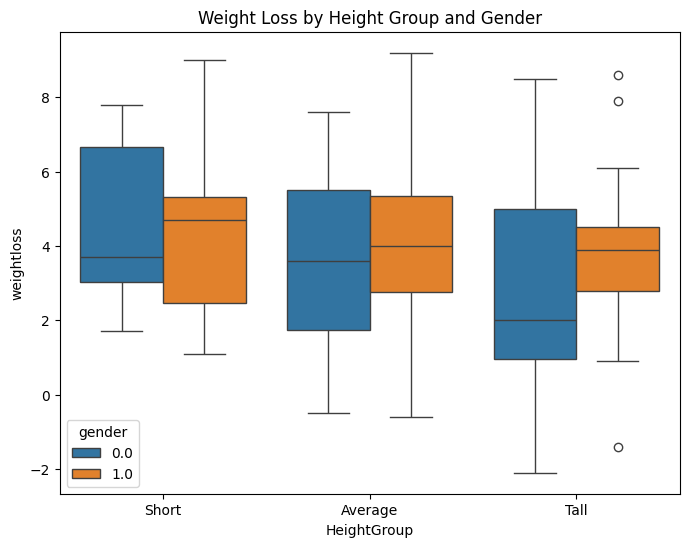

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='HeightGroup', y='weightloss', hue='gender', data=diet_df)
plt.title('Weight Loss by Height Group and Gender')
plt.show()

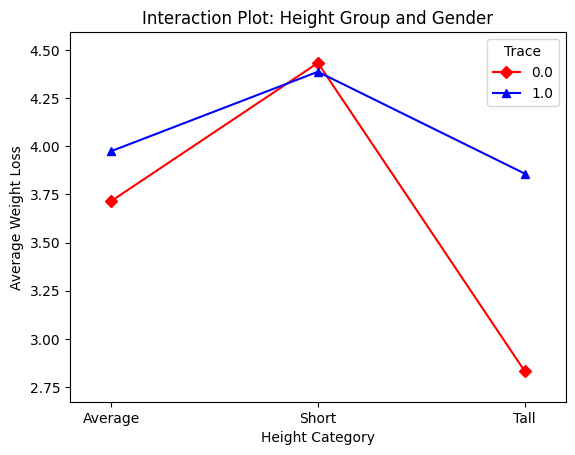

In [ ]:
from statsmodels.graphics.factorplots import interaction_plot

# Creating the interaction plot
fig = interaction_plot(x=diet_df['HeightGroup'].astype(str).values,
                       trace=diet_df['gender'].values,
                       response=diet_df['weightloss'].values,
                       colors=['red', 'blue'], markers=['D', '^'])

plt.xlabel("Height Category")
plt.ylabel("Average Weight Loss")
plt.title("Interaction Plot: Height Group and Gender")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.graphics.factorplots import interaction_plot

diet_df = pd.read_excel('Diet_R (2).xlsx')
diet_df['gender'] = pd.to_numeric(diet_df['gender'], errors='coerce')
diet_df.dropna(subset=['gender'], inplace=True)
diet_df.reset_index(drop=True, inplace=True)

diet_df['weightloss'] = diet_df['pre.weight'] - diet_df['weight6weeks']

diet_df['WeightCategory'] = pd.qcut(diet_df['pre.weight'], q=3, labels=['Light', 'Moderate', 'Heavy'])

print(diet_df[['pre.weight', 'WeightCategory', 'Diet', 'weightloss']].head())

   pre.weight WeightCategory  Diet  weightloss
0          58          Light     1         3.8
1          60          Light     1         6.0
2          64          Light     1         0.7
3          64          Light     1         2.9
4          65          Light     1         2.8


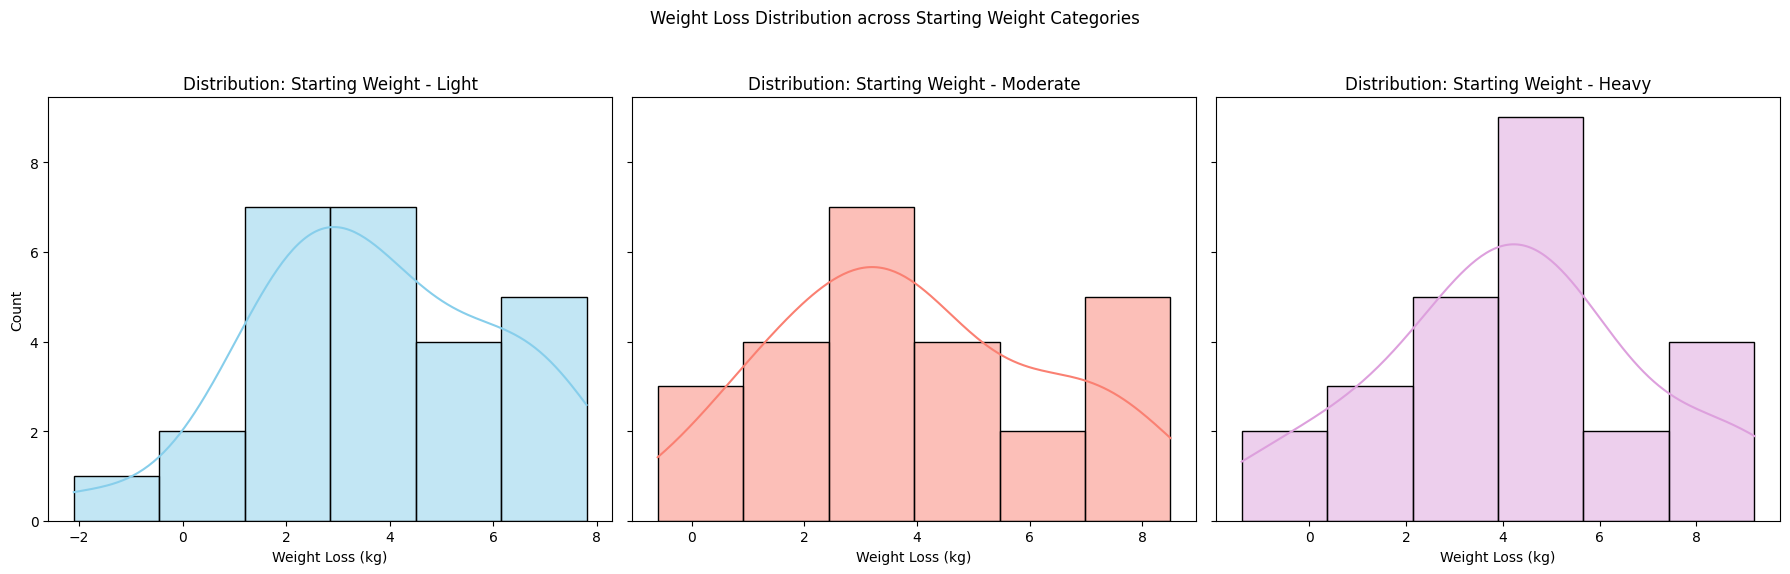

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

sns.histplot(diet_df[diet_df.WeightCategory == 'Light'].weightloss, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution: Starting Weight - Light')
axes[0].set_xlabel('Weight Loss (kg)')

sns.histplot(diet_df[diet_df.WeightCategory == 'Moderate'].weightloss, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution: Starting Weight - Moderate')
axes[1].set_xlabel('Weight Loss (kg)')

sns.histplot(diet_df[diet_df.WeightCategory == 'Heavy'].weightloss, kde=True, ax=axes[2], color='plum')
axes[2].set_title('Distribution: Starting Weight - Heavy')
axes[2].set_xlabel('Weight Loss (kg)')

plt.suptitle('Weight Loss Distribution across Starting Weight Categories')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

One-Way ANOVA (WeightCategory) F-statistic: 0.23504867431302615
One-Way ANOVA (WeightCategory) P-value: 0.791128329318094


/tmp/ipykernel_11078/594995692.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='WeightCategory', y='weightloss', data=diet_df, palette='Set2')


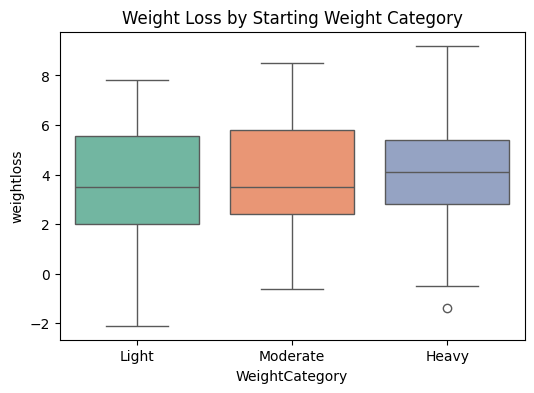

In [ ]:
w_light = diet_df[diet_df['WeightCategory'] == 'Light']['weightloss']
w_mod = diet_df[diet_df['WeightCategory'] == 'Moderate']['weightloss']
w_heavy = diet_df[diet_df['WeightCategory'] == 'Heavy']['weightloss']

f_stat, p_val = stats.f_oneway(w_light, w_mod, w_heavy)
print(f"One-Way ANOVA (WeightCategory) F-statistic:", f_stat)
print(f"One-Way ANOVA (WeightCategory) P-value:", p_val)

plt.figure(figsize=(6, 4))
sns.boxplot(x='WeightCategory', y='weightloss', data=diet_df, palette='Set2')
plt.title('Weight Loss by Starting Weight Category')
plt.show()

Two-Way ANOVA Results (WeightCategory & Diet):
                               sum_sq    df         F    PR(>F)
C(WeightCategory)            2.495644   2.0  0.214544  0.807462
C(Diet)                     60.009421   2.0  5.158844  0.008244
C(WeightCategory):C(Diet)   18.222804   4.0  0.783282  0.540037
Residual                   389.683360  67.0       NaN       NaN


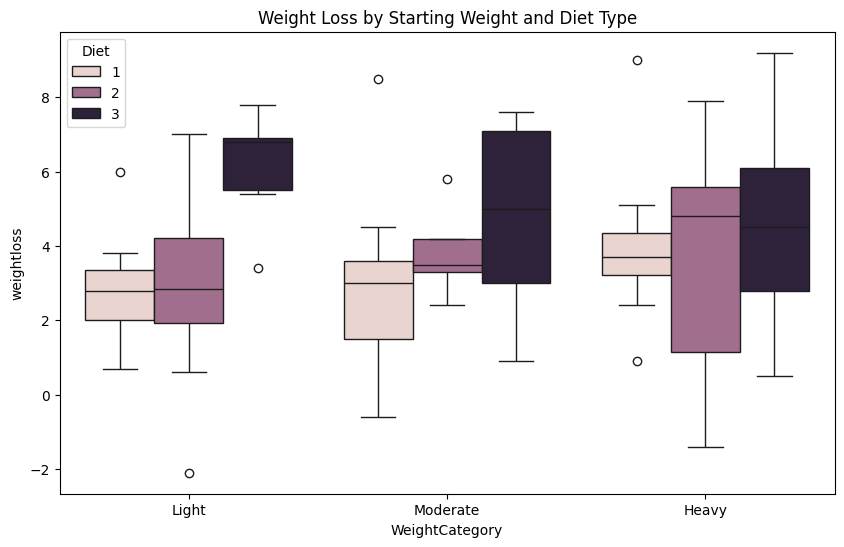

In [ ]:
# Statistical Model for 2-Way ANOVA
model = ols('weightloss ~ C(WeightCategory) + C(Diet) + C(WeightCategory):C(Diet)', data=diet_df).fit()
anova_results = sm.stats.anova_lm(model, typ=2)
print("Two-Way ANOVA Results (WeightCategory & Diet):")
print(anova_results)

plt.figure(figsize=(10, 6))
sns.boxplot(x='WeightCategory', y='weightloss', hue='Diet', data=diet_df)
plt.title('Weight Loss by Starting Weight and Diet Type')
plt.show()

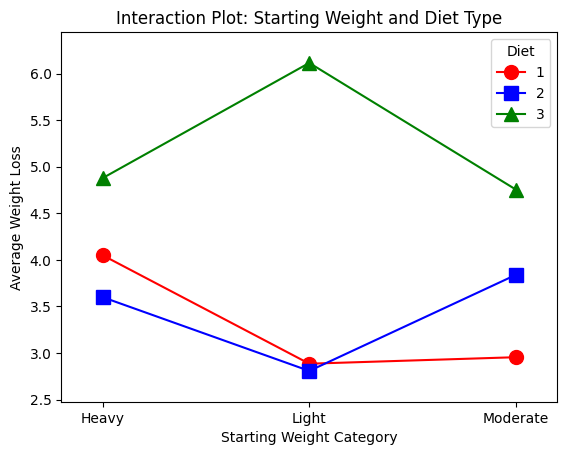

In [ ]:

fig = interaction_plot(x=diet_df['WeightCategory'].astype(str),
                       trace=diet_df['Diet'],
                       response=diet_df['weightloss'],
                       colors=['red', 'blue', 'green'], markers=['o', 's', '^'], ms=10)

plt.xlabel("Starting Weight Category")
plt.ylabel("Average Weight Loss")
plt.title("Interaction Plot: Starting Weight and Diet Type")
plt.show()